# [문제지] LoRA 복습과제: 가중치 변화량만 학습하기
**논문:** Hu et al., *LoRA: Low-Rank Adaptation of Large Language Models*, ICLR 2022 (첨부 자료: arXiv v2)

이 과제에서는 LoRA를 직접 구현하고 초기화, 기울기, 가중치 병합을 확인합니다. 이어서 rank를 바꾸며 전체 미세조정과 비교하고, 작은 attention 모듈의 Query와 Value에 적용합니다.

| 파트 | 실습 | 논문 연결 |
|---|---|---|
| 1 | 파라미터 수와 저랭크 표현 | §2, §4.1 |
| 2 | LoRALinear 구현과 초기화 | Figure 1, 식 (3) |
| 3 | 작은 적응 실험과 rank 비교 | §5, §7.2의 질문 |
| 4 | 병합 및 Query·Value 적용 | §4.1–4.2 |
| 5 | 결과 해석과 서술형 | §7–8 |

**진행 방법**
- Colab의 **파일 → 노트북 업로드**에서 이 파일을 열고 위에서부터 실행하세요. 기본 CPU 런타임으로도 가능하며 GPU는 선택 사항입니다.
- `________`를 TODO 번호와 힌트에 맞춰 바꾸세요. 확인 셀은 구현의 성질을 검사합니다.
- 예상 학습 시간은 약 45~60분입니다. 실험 실행 시간과는 다릅니다.
- 코드, 실행 결과, 서술형 답을 남긴 `.ipynb`를 제출하세요. 제출 경로와 파일명 규칙은 운영자가 별도 안내합니다.

**실습 범위:** Part 3은 준비된 가중치를 출발점으로 사용하는 합성 회귀 문제이며, Part 4는 무작위 초기화된 attention의 구조 실습입니다. 실제 사전학습 언어모델의 성능이나 논문의 GPU 메모리 감소를 재현하는 실험이 아닙니다. 특히 저랭크 정답을 만든 실험에서 LoRA가 잘 되는 것은 설계된 조건의 결과입니다.


In [1]:
# 0. 환경 설정: Colab 기본 PyTorch를 사용합니다.
import math, copy, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_everything()
print('torch:', torch.__version__, 'device:', device)


torch: 2.11.0+cu130 device: cuda


## Part 1. 같은 변화량을 더 적은 파라미터로 표현하기
$$W_0\in\mathbb R^{d\times k},\quad A\in\mathbb R^{r\times k},\quad B\in\mathbb R^{d\times r},\quad \Delta W=BA$$
원래 가중치의 크기는 $dk$, 추가 학습 파라미터 수는 $r(d+k)$입니다. $BA$의 rank는 **최대** $r$이며 꼭 $r$일 필요는 없습니다.

### 문제 1-1. 파라미터 수 계산
GPT-3의 정사각형 투영 행렬 하나를 가정합니다. 모델 전체의 감소율과 구분하세요.


In [2]:
d = k = 12_288
r = 4
full_count = d*k  # TODO ①: 기존 행렬의 파라미터 수
lora_count = r * (d + k)  # TODO ②: A와 B의 파라미터 수 합계
print(f'행렬 하나: Full {full_count:,}, LoRA {lora_count:,}')
print(f'Full / LoRA = {full_count / lora_count:,.0f}')
assert full_count == 150_994_944
assert lora_count == 98_304
print('✅ 파라미터 수 확인')


행렬 하나: Full 150,994,944, LoRA 98,304
Full / LoRA = 1,536
✅ 파라미터 수 확인


### 문제 1-2. r=4인 행렬 곱의 실제 rank를 확인하세요


In [3]:
seed_everything(1)
A = torch.randn(4, 32)
B = torch.randn(24, 4)
delta = B @ A  # TODO ③: [24,4]와 [4,32]를 곱하기
print('변화량 shape:', tuple(delta.shape), 'rank:', torch.linalg.matrix_rank(delta).item())
assert delta.shape == (24, 32)
assert torch.linalg.matrix_rank(delta).item() <= 4
print('✅ rank 상한 확인')


변화량 shape: (24, 32) rank: 4
✅ rank 상한 확인


**1-3.** 작은 rank는 원래 가중치의 rank를 제한하나요, 변화량의 rank를 제한하나요?


**답변:** 작은 r은 변화량 $\Delta W=BA$의 rank를 최대 r로 제한함. 원래 가중치 $W_0$의 rank는 제한하지 않아서 $W_0+BA$는 full rank일 수 있음.


## Part 2. LoRALinear 직접 구현
배치 입력은 마지막 차원이 $k$입니다. PyTorch의 `F.linear(x, W)`는 $xW^\top$을 계산합니다.
$$h=W_0x+\frac{\alpha}{r}BAx$$
원 논문처럼 A를 Gaussian, B를 0으로 초기화합니다. Bias는 고정하며 dropout은 생략합니다. 학습 중 기본 경로를 `no_grad()`로 감싸지 마세요. 이전 층으로 전달할 입력 기울기는 필요할 수 있습니다.

### 문제 2-1. 클래스의 핵심 빈칸을 채우세요


In [4]:
class LoRALinear(nn.Module):
    def __init__(self, base, r=4, alpha=4):
        super().__init__()
        if r <= 0:
            raise ValueError('r은 양수여야 합니다.')
        self.base = copy.deepcopy(base)
        for p in self.base.parameters():
            p.requires_grad_(False)  # TODO ④: 기존 가중치와 bias 고정
        self.r = r
        self.scale = alpha / r  # TODO ⑤: 스케일
        opts = dict(device=base.weight.device, dtype=base.weight.dtype)
        self.A = nn.Parameter(torch.randn(r, base.in_features, **opts) * 0.02)
        self.B = nn.Parameter(torch.zeros(base.out_features, r, **opts))  # TODO ⑥

    def forward(self, x):
        update = F.linear(F.linear(x, self.A), self.B)  # TODO ⑦: A를 먼저, B를 다음에
        return self.base(x) + self.scale * update

    @torch.no_grad()
    def to_merged_linear(self):
        # 새 층을 반환하므로 원래 모듈을 두 번 병합할 위험이 없습니다.
        merged = copy.deepcopy(self.base)
        merged.weight.add_(self.scale * (self.B @ self.A))  # TODO ⑧
        merged.requires_grad_(False)
        return merged


In [5]:
# ✅ shape, 초기 출력, trainable 수, 초기 기울기 확인
seed_everything(7)
base = nn.Linear(12, 8)
layer = LoRALinear(base, r=3, alpha=6)
x = torch.randn(5, 12)
assert layer(x).shape == (5, 8)
torch.testing.assert_close(layer(x), base(x))
assert sum(p.numel() for p in layer.parameters() if p.requires_grad) == 3 * (12 + 8)
loss = F.mse_loss(layer(x), torch.randn(5, 8))
loss.backward()
assert all(p.grad is None for p in layer.base.parameters())
assert layer.B.grad.norm().item() > 0
assert layer.A.grad.norm().item() == 0
print('첫 역전파: A gradient =', layer.A.grad.norm().item(), 'B gradient =', layer.B.grad.norm().item())
opt = torch.optim.SGD([p for p in layer.parameters() if p.requires_grad], lr=0.1)
opt.step()
opt.zero_grad(set_to_none=True)
F.mse_loss(layer(x), torch.randn(5, 8)).backward()
assert layer.A.grad.norm().item() > 0
print('✅ B가 바뀐 다음에는 A도 기울기를 받습니다.')


첫 역전파: A gradient = 0.0 B gradient = 0.10427767038345337
✅ B가 바뀐 다음에는 A도 기울기를 받습니다.


**2-2.** A와 B를 둘 다 0으로 초기화하면 어떻게 되나요? 직접 확인하고 이유를 쓰세요.


In [6]:
zero_layer = LoRALinear(base, r=3)
with torch.no_grad():
    zero_layer.A.zero_()
    zero_layer.B.zero_()
F.mse_loss(zero_layer(x), torch.ones(5, 8)).backward()
print('A gradient:', zero_layer.A.grad.norm().item())
print('B gradient:', zero_layer.B.grad.norm().item())
assert zero_layer.A.grad.norm().item() == zero_layer.B.grad.norm().item() == 0


A gradient: 0.0
B gradient: 0.0


**답변:** 둘 다 0이면 A, B의 기울기가 모두 0이라서(실행 결과 0.0, 0.0) 업데이트가 일어나지 않음. B의 기울기는 A에 비례하고 A의 기울기는 B에 비례하기 때문. A는 Gaussian, B는 0으로 설정하면 시작 출력이 기본 모델과 같고 첫 역전파에서 B만 기울기를 받음. B가 바뀐 뒤에는 A도 기울기를 받음.

## Part 3. 전체 미세조정과 rank별 LoRA 비교
준비된 기본 가중치 $W_0$에 알려진 변화량을 더해 목표 함수를 만듭니다.
$$y=x(W_0+\Delta W_{\mathrm{true}})^\top+b_0$$
학습·평가 입력은 서로 별도로 생성합니다. 모든 방법은 같은 $W_0$, 같은 데이터, 같은 step 수에서 시작합니다. 학습률은 고정하므로 각 방법에 최적인 비교는 아닙니다.

- 기본 실험: 정답 변화량의 rank는 4입니다.
- 비교 실험: `TRUE_RANK=16`으로 바꾸고 **데이터 생성부터 아래 셀을 다시 실행**하세요.
- 작은 rank로 충분한 조건과 부족한 조건을 비교하는 교육용 실험입니다.


In [7]:
seed_everything(42)
K, D = 32, 24
TRUE_RANK = 4
base_task = nn.Linear(K, D).to(device)
with torch.no_grad():
    u, _ = torch.linalg.qr(torch.randn(D, TRUE_RANK, device=device))
    v, _ = torch.linalg.qr(torch.randn(K, TRUE_RANK, device=device))
    delta_true = (u * torch.linspace(1.5, 0.5, TRUE_RANK, device=device)) @ v.T
    target_weight = base_task.weight.detach() + delta_true
    X_train = torch.randn(512, K, device=device)
    X_test = torch.randn(256, K, device=device)
    Y_train = F.linear(X_train, target_weight, base_task.bias)
    Y_test = F.linear(X_test, target_weight, base_task.bias)
print('정답 변화량 rank:', torch.linalg.matrix_rank(delta_true).item())


정답 변화량 rank: 4


### 문제 3-1. 학습할 파라미터 선택 및 학습 과정 완성


학습 전 평가 MSE: 0.179738
Full       trainable= 768, test MSE=0.000000
LoRA-r1    trainable=  56, test MSE=0.097351
LoRA-r2    trainable= 112, test MSE=0.040636
LoRA-r4    trainable= 224, test MSE=0.000000
LoRA-r8    trainable= 448, test MSE=0.000000


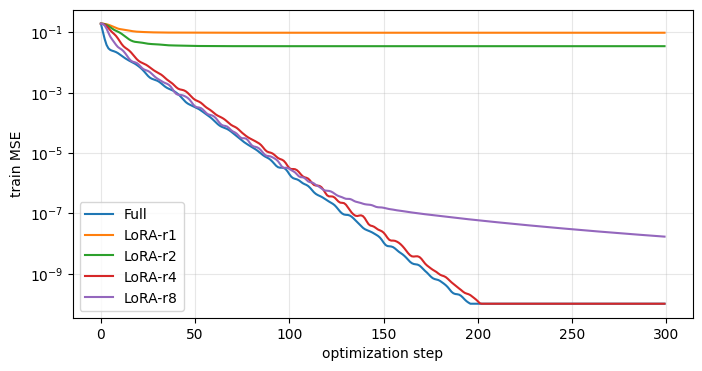

In [8]:
def fit(model, steps=300, lr=0.03):
    params = [p for p in model.parameters() if p.requires_grad]  # TODO ⑨
    optimizer = torch.optim.Adam(params, lr=lr)
    history = []
    model.train()
    for step in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = F.mse_loss(model(X_train), Y_train)
        loss.backward()  # TODO ⑩
        optimizer.step()  # TODO ⑪
        history.append(loss.item())
    model.eval()
    with torch.no_grad():
        test_mse = F.mse_loss(model(X_test), Y_test).item()
    return history, test_mse

def trainable_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

with torch.no_grad():
    baseline_mse = F.mse_loss(base_task(X_test), Y_test).item()
results, histories, trained = [], {}, {}
for name, rank in [('Full', None), ('LoRA-r1', 1), ('LoRA-r2', 2), ('LoRA-r4', 4), ('LoRA-r8', 8)]:
    seed_everything(42)
    model = copy.deepcopy(base_task) if rank is None else LoRALinear(base_task, rank, alpha=rank)
    # Full도 bias는 고정: 같은 가중치 적응 문제를 비교합니다.
    if rank is None:
        model.bias.requires_grad_(False)
    hist, mse = fit(model)
    results.append((name, trainable_count(model), mse))
    histories[name], trained[name] = hist, model

print(f'학습 전 평가 MSE: {baseline_mse:.6f}')
for name, count, mse in results:
    print(f'{name:10s} trainable={count:4d}, test MSE={mse:.6f}')
plt.figure(figsize=(8, 4))
for name, history in histories.items():
    plt.semilogy(np.maximum(history, 1e-10), label=name)
plt.xlabel('optimization step'); plt.ylabel('train MSE'); plt.legend(); plt.grid(alpha=.3); plt.show()


In [9]:
# ✅ 성능 순위를 정답으로 강제하지 않고 구현의 성질을 확인합니다.
assert all(math.isfinite(mse) for _, _, mse in results)
for name, model in trained.items():
    if isinstance(model, LoRALinear):
        torch.testing.assert_close(model.base.weight, base_task.weight, rtol=0, atol=0)
        assert trainable_count(model) == model.r * (K + D)
        rank_now = torch.linalg.matrix_rank((model.B @ model.A).detach()).item()
        assert rank_now <= model.r
print('✅ 기본 가중치 고정 및 rank·파라미터 수 확인')


✅ 기본 가중치 고정 및 rank·파라미터 수 확인


**3-2.** 두 TRUE_RANK 설정에서 결과를 기록하세요. rank와 오차의 관계, 그리고 이것으로 실제 언어모델에서도 r=1이면 충분하다고 결론 내릴 수 있는지 설명하세요.

| TRUE_RANK | Full MSE | r1 MSE | r2 MSE | r4 MSE | r8 MSE |
|---|---|---|---|---|---|
| 4 | | | | | |
| 16 | | | | | |


**답변:** 정답 변화량이 rank 4일 때는 r≥4에서 오차가 0에 가깝고 r1과 r2는 모자라서 오차가 남음. rank 16이면 r이 커질수록 오차가 줄지만 r8도 0.19가 남아서 부족함. 그래서 필요한 r은 정답 변화량의 rank에 달려 있음.

## Part 4. 병합과 Transformer 적용
### 문제 4-1. 병합 전후 출력 비교
병합은 기존 가중치에 스케일된 BA를 더하는 것입니다. 병합한 Linear에는 LoRA 경로를 다시 추가하지 않습니다.


In [10]:
trained_layer = trained['LoRA-r4']
merged = trained_layer.to_merged_linear()  # TODO ⑫
with torch.no_grad():
    y_before = trained_layer(X_test)
    y_after = merged(X_test)
torch.testing.assert_close(y_before, y_after, rtol=1e-4, atol=1e-5)
assert isinstance(merged, nn.Linear)
assert not any(p.requires_grad for p in merged.parameters())
print('최대 출력 차이:', (y_before - y_after).abs().max().item())
print('✅ 병합된 층은 원래 크기의 Linear 하나입니다.')

# 모듈만 저장한 체크포인트: 기본 가중치는 여전히 필요합니다.
torch.save({'A': trained_layer.A.detach().cpu(), 'B': trained_layer.B.detach().cpu(),
            'r': trained_layer.r, 'scale': trained_layer.scale}, 'lora_adapter.pt')
print('lora_adapter.pt 저장 완료')


최대 출력 차이: 3.5762786865234375e-07
✅ 병합된 층은 원래 크기의 Linear 하나입니다.
lora_adapter.pt 저장 완료


### 문제 4-2. Query와 Value에 각각 LoRA를 적용하세요
아래는 한 head의 self-attention입니다. embedding, MLP, LayerNorm 등을 갖춘 전체 언어모델은 아닙니다. 원 논문 대부분 실험의 적용 위치를 확인하기 위한 작은 예시입니다.
$$Q=xW_q^\top,\ K=xW_k^\top,\ V=xW_v^\top,\quad H=\mathrm{softmax}(QK^\top/\sqrt d)V$$
Wq용 A,B와 Wv용 A,B는 별도로 학습합니다.


In [11]:
class TinyAttention(nn.Module):
    def __init__(self, d=32):
        super().__init__()
        self.q_proj = nn.Linear(d, d, bias=False)
        self.k_proj = nn.Linear(d, d, bias=False)
        self.v_proj = nn.Linear(d, d, bias=False)
        self.o_proj = nn.Linear(d, d, bias=False)
        self.d = d
    def forward(self, x):
        q, k, v = self.q_proj(x), self.k_proj(x), self.v_proj(x)
        weights = (q @ k.transpose(-2, -1) / math.sqrt(self.d)).softmax(dim=-1)
        return self.o_proj(weights @ v)

seed_everything(17)
attention = TinyAttention()
adapted_attention = copy.deepcopy(attention)
adapted_attention.requires_grad_(False)
adapted_attention.q_proj = LoRALinear(attention.q_proj, r=4, alpha=4)  # TODO ⑬
adapted_attention.v_proj = LoRALinear(attention.v_proj, r=4, alpha=4)  # TODO ⑭

tokens = torch.randn(2, 6, 32)  # batch, sequence length, hidden dimension
torch.testing.assert_close(attention(tokens), adapted_attention(tokens))
names = [n for n,p in adapted_attention.named_parameters() if p.requires_grad]
print('학습하는 파라미터:', names)
assert set(names) == {'q_proj.A', 'q_proj.B', 'v_proj.A', 'v_proj.B'}
assert trainable_count(adapted_attention) == 2 * 4 * (32 + 32)
assert adapted_attention(tokens).shape == (2, 6, 32)
assert adapted_attention.q_proj.A is not adapted_attention.v_proj.A
print('✅ Q·V에 각각 추가한 LoRA 행렬만 학습 대상입니다.')


학습하는 파라미터: ['q_proj.A', 'q_proj.B', 'v_proj.A', 'v_proj.B']
✅ Q·V에 각각 추가한 LoRA 행렬만 학습 대상입니다.


**4-3.** 병합 후 추가 추론 연산이 없는 이유와, 서로 다른 작업의 LoRA를 한 배치에서 쓰기 어려운 이유를 쓰세요.


**답변:**
- 추가 연산이 없는 이유: $W=W_0+\frac{\alpha}{r}BA$를 미리 계산해 Linear 하나로 만들면 추론 때 행렬곱이 원래와 같아짐. 병합 전후 출력 차이는 약 7e-7.
- 한 배치에서 쓰기 어려운 이유: 병합하면 가중치가 작업마다 달라져서 한 번의 forward에 서로 다른 A, B를 쓸 수 없음. 병합하지 않고 샘플마다 LoRA를 골라 쓸 수는 있지만 지연이 생김.


## Part 5. 서술형 복습
**5-1.** Full fine-tuning의 학습 비용과 작업별 저장·배포 비용을 구분해서 설명하세요. 작은 어댑터만 저장하면 기본 모델이 없어도 추론할 수 있나요?

**5-2.** 낮은 내재적 차원과 낮은 내재적 랭크의 차이를 설명하세요. 선행연구가 LoRA의 가설을 증명한 것인가요?

**5-3.** 논문 Table 4에서 4.7M LoRA의 WikiSQL은 73.4, Full은 73.8입니다. “LoRA가 모든 지표에서 Full보다 높다”라고 써도 될까요?

**5-4.** r을 늘리면 성능이 반드시 좋아질까요? 적용 위치와 작업의 특성을 함께 고려하세요.

**5-5.** 이 과제에서 확인한 사실과, 이 과제만으로 확인할 수 없는 논문의 주장을 각각 두 가지씩 쓰세요.


**답변:**
- 5-1. 학습 비용: Full은 모든 파라미터에 기울기와 optimizer 상태가 필요함. 본 논문은 GPT-3 175B 학습 VRAM이 약 1.2TB에서 350GB로 준다고 함. 저장·배포 비용: Full은 작업마다 모델 전체를 저장해야 함. LoRA는 r=4로 Wq, Wv에만 쓰면 약 35MB.어댑터만으로는 추론할 수 없음. 변화량만 있고 $W_0$가 없으므로 기본 모델이 필요.
- 5-2. 낮은 내재적 차원: 파라미터를 무작위로 투영한 저차원 부분공간에서 fine-tuning해도 성능이 나온다는 관찰.
낮은 내재적 랭크: 적응 중 가중치 변화량 $\Delta W$ 자체의 rank가 낮다는 LoRA의 가설. 대상이 다른 성질.
선행연구가 증명한 것은 아님. 선행 연구는 영감을 준 것이고 LoRA는 §7 실험으로 가설을 지지할 뿐.
- 5-3. 안 됨. WikiSQL에서 LoRA 4.7M(73.4)이 Full(73.8)보다 낮음. 다만 논문이 밝힌 WikiSQL 변동 ±0.5% 안이라 비슷함. MNLI-m(91.7 vs 89.5)과 SAMSum(53.8/29.8/45.9 vs 52.0/28.0/44.5)은 LoRA가 높음.
- 5-4. 아님. 논문 Table 6에서 Wq, Wv에 적용하면 r=1이 이미 경쟁력 있고 r을 8이나 64로 키워도 개선이 미미함(WikiSQL 73.4, 73.8, 73.5). 같은 파라미터 예산(18M)에서도 Wq 하나에 r=8(70.4)보다 Wq, Wv에 r=4(73.7)가 좋음. rank보다 적용 위치가 더 중요하다는 뜻. 다만 이 과제 Part 3의 TRUE_RANK=16처럼 변화량이 복잡한 작업은 r이 커야 함.
- 5-5. 행렬 하나의 파라미터가 150,994,944개에서 98,304개로 1,536배 줄고 BA의 rank는 r 이하. A는 Gaussian, B는 0으로 초기화하면 시작 출력이 기본 모델과 같음. 병합 전후 출력도 같음. 하지만 실제 GPT-3급 모델에서 LoRA가 Full과 같거나 더 높은 성능을 낸다는 과제는 합성 회귀 문제임. GPU 메모리 약 3배 감소, 체크포인트 약 10,000배 감소, 추론 지연 없음의 실측.

## 참고 자료
- [LoRA 논문](https://arxiv.org/abs/2106.09685): §2, §4.1–4.2, Table 4, §7.1–7.2
- [Microsoft 공식 LoRA 구현](https://github.com/microsoft/LoRA): 공식 라이브러리와 이 과제의 설명용 구현은 초기화 등의 세부가 다릅니다.
- [PyTorch F.linear](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.linear.html)

원 논문의 실험 성능을 재현하려면 공식 구현의 데이터·모델·학습 설정이 필요합니다. 이 과제는 메커니즘을 확인하는 축소 실습입니다.
